# CBEM — MC / VC stimulation (thin driver notebook)

All logic lives in the `cbem/` package; this notebook only sets options and calls it.
See `README.md` for the model, the data format, the simultaneous-condition analysis and troubleshooting.

**Run this notebook from the project folder** (the one that contains `cbem/`).

In [14]:
%load_ext autoreload
%autoreload 2
import matplotlib
%matplotlib inline
import os, sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))     # so `import cbem` works
import numpy as np
import pandas as pd
from cbem import config, data, model, fitting, analysis, plotting
from cbem.config import DT
print('numba available:', model.HAS_NUMBA, '(pip install numba if False)')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
numba available: True (pip install numba if False)


## Settings — edit this cell

In [15]:
MAT_FILE     = 'C:/Users/sofik/Downloads/CBEM8_small.mat'
MAT_VARIABLE = 'CBEM8'    # variable name inside the .mat (None = auto-detect if only one)
OUT_DIR      = 'outputs'      # figures (PDF), cached fit, summary table

FILTER_LEN   = 150            # ms of stimulus history per filter
HIST_LEN     = 30             # ms of post-spike history
LAMBDA_L2    = 0.0            # L2 penalty on stimulus filters (overwritten by the grid search)
PASSES       = config.FULL_PASSES   # optimiser passes; use config.FAST_PASSES for a quick look

RUN_GRID_SEARCH = True       # True: pick FILTER_LEN / HIST_LEN / LAMBDA_L2 first (section 3)
REFIT           = True        # False: load OUT_DIR/cbem_results.pkl instead of refitting
RUN_CROSSVAL    = True        # refits on 80 % of every segment -> doubles fitting time

BIOPHYS = dict(config.BIOPHYS)   # update from your patch data (see README)

os.makedirs(OUT_DIR, exist_ok=True)
RESULTS_FILE = f'{OUT_DIR}/cbem_results.pkl'

## 1. Load data, split MC / VC, sanity check

43010 bins = 43.0 s at 1 kHz, 1 neurons
Proto Name                             Dur(s)   MC_ON   VC_ON   spk1
1     VC single pulses                    5.0       0      56     35
2     VC 100Hz trains                     9.3       0     289    201
3     MC single pulses                    5.0      30       0    217
4     MC 100Hz trains                     9.3     289       0     36
5     Simultaneous single pulses          5.1     105     105     38
6     Simultaneous 100Hz trains           9.3     287     287     14


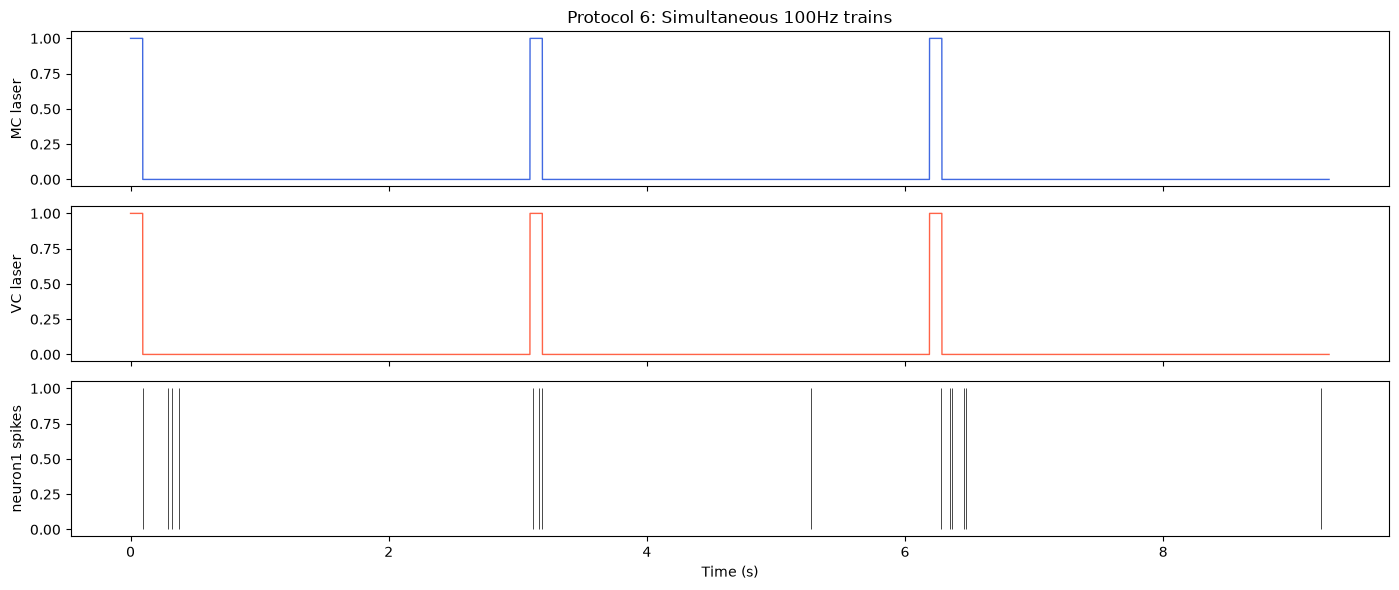

In [16]:
raw = data.load_raw(MAT_FILE, MAT_VARIABLE)
ds = data.prepare_dataset(raw)
data.describe_dataset(ds)
plotting.plot_sanity(ds, protocol=6, nidx=1, outdir=OUT_DIR)   # spikes should follow the pulses

## 2. Fit set (protocols 2, 4, 6)

In [22]:
fit = data.build_fit_set(ds, config.FIT_PROTOCOLS)
print(f'{fit.T} bins = {fit.T * DT:.0f} s in {len(fit.segments)} segments')
for n, y in fit.spikes.items():
    print(f'  {n}: {int(y.sum())} spikes ({y.sum() / (fit.T * DT):.1f} Hz)')

27858 bins = 28 s in 3 segments
  neuron1: 251 spikes (9.0 Hz)


## 3. (Optional) Hyper-parameter grid search
Ranks `filter_len x hist_len x lambda_l2` by the **worst** validation loss across neurons on a short,
protocol-balanced subset. The chosen lambda is rescaled to the full data size automatically.

In [24]:
if RUN_GRID_SEARCH:
    GRID = {'filter_len': [50, 100, 150], 'hist_len': [20, 30], 'lambda_l2': [0.0, 1e-3, 1e-2]}
    try:
        records, best = fitting.grid_search(fit, GRID, DT, BIOPHYS, search_secs=40)
    except ValueError as e:   # e.g. a short file with too few validation spikes
        print(f'Grid search skipped: {e}')
        print(f'Keeping filter_len={FILTER_LEN}, hist_len={HIST_LEN}, lambda_l2={LAMBDA_L2}')
    else:
        plotting.plot_gridsearch(records, GRID, best, OUT_DIR)
        FILTER_LEN, HIST_LEN = best['fl'], best['hl']
        LAMBDA_L2 = fitting.scale_lambda(best['lambda'], best['n_train_bins'], fit.T)
        print(f'Using filter_len={FILTER_LEN}, hist_len={HIST_LEN}, lambda_l2={LAMBDA_L2:.3g} (rescaled)')
else:
    print('Grid search skipped (RUN_GRID_SEARCH = False)')

neuron1: skipped (only 2 validation spikes in subset)


ValueError: No neuron has enough validation spikes; raise search_secs

## 4. Fit all neurons

In [19]:
fl, hl = FILTER_LEN, HIST_LEN
loaded = (not REFIT) and os.path.exists(RESULTS_FILE)
if loaded:
    results = fitting.load_results(RESULTS_FILE)
    first = next(iter(results.values()))
    fl, hl, LAMBDA_L2 = first['fl'], first['hl'], first['lambda_l2']
    print(f'Loaded cached fit: filter_len={fl}, hist_len={hl}, lambda_l2={LAMBDA_L2:.3g}')
Xd = data.make_design_matrix(fit.X, fl, fit.segments)
if not loaded:
    results = fitting.fit_all(fit, Xd, fl, hl, DT, BIOPHYS, LAMBDA_L2, PASSES)
    fitting.save_results(results, RESULTS_FILE)

Fitting neuron1 (251 spikes, 9.0 Hz)



KeyboardInterrupt: 

## A. Cross-validation (nats per spike; lower is better)

In [ ]:
if RUN_CROSSVAL:
    cv = fitting.cross_validate(fit, Xd, fl, hl, DT, BIOPHYS, LAMBDA_L2, passes=PASSES)
    plotting.plot_crossval(cv, OUT_DIR)
else:
    cv = None

## 5. Filters, peak latencies / widths (D) and E/I ratio

In [ ]:
plotting.plot_filters(results, DT, OUT_DIR)
ftab = analysis.filter_table(results, DT)
display(ftab)
plotting.plot_filter_stats(ftab, OUT_DIR)
ei = analysis.ei_table(results, DT)
display(ei)
plotting.plot_ei(ei, OUT_DIR)

## 6. Conductances and voltage-vs-history decomposition (C)

In [ ]:
NEURON, PROTOCOL = 'neuron1', 3
nidx = int(NEURON.replace('neuron', ''))
dec = analysis.decompose(ds, results[NEURON]['params'], nidx, PROTOCOL, fl, hl, DT, BIOPHYS,
                         start_bin=0, n_bins=10000)
title = f'{NEURON} - protocol {PROTOCOL}: {config.PROTOCOL_NAMES[PROTOCOL]}'
plotting.plot_conductances(dec, title, OUT_DIR)
plotting.plot_decomposition(dec, title, OUT_DIR)

## 7. Simultaneous condition
MC-only vs VC-only vs simultaneous (protocol 5): conductances, predicted vs observed rate,
spike-count modulation index, and the baseline-corrected conductance summation test.

In [ ]:
window = analysis.simultaneous_predictions(ds, results, fl, hl, DT, BIOPHYS, protocol=5, n_sec=10)
plotting.plot_simultaneous(results, OUT_DIR)
plotting.plot_rate_comparison(ds, results, window, outdir=OUT_DIR)

mi = analysis.modulation_index(ds, results)       # (VC, MC, simultaneous) = protocols 1, 3, 5
display(mi)
plotting.plot_mi(mi, OUT_DIR)

summ = analysis.summation_test(results)           # alpha = beta = 1: linear
display(summ)
plotting.plot_summation(results, summ, OUT_DIR)

## 8. PSTH vs predicted rate (B)

In [ ]:
PSTH_PATHWAYS = {'MC': (0, [3, 4]), 'VC': (1, [1, 2]), 'Simultaneous': (0, [5, 6])}   # (channel, protocols)
psths = {}
for name, r in results.items():
    nidx = int(name.replace('neuron', ''))
    for label, (ch, protos) in PSTH_PATHWAYS.items():
        psths[(name, label)] = analysis.psth(ds, r['params'], nidx, fl, hl, DT, BIOPHYS, ch, protos,
                                             pre_ms=20, post_ms=100)
plotting.plot_psth(psths, OUT_DIR)

## 9. Summary

In [ ]:
summary = analysis.summary_table(results, cv, mi, summ)
display(summary)
summary.to_csv(f'{OUT_DIR}/cbem_summary.csv', index=False)
print('Figures and tables saved in', OUT_DIR)

In [ ]:
from cbem.modulation import observed_modulation, model_modulation, plot_modulation
import pandas as pd

rows = observed_modulation(raw)        # raw = mat['CBEM8'], the full matrix
mi = pd.DataFrame(rows)
display(mi[['Neuron', 'Stimulus', 'R_mc (Hz)', 'R_vc (Hz)', 'R_sim (Hz)',
            'Additivity index', 'Result', 'Warnings']])
plot_modulation(rows, 'CBEM8');

In [ ]:
from cbem.data import make_design_matrix
from cbem.model import forward
res = results['neuron1']
pd.DataFrame(model_modulation(res['params'], res['fl'], res['hl'],
                              ds.X_full, ds.protocol_1k, DT, BIOPHYS,
                              make_design_matrix, forward))

In [ ]:
# Modulation three ways: data only (OBS), model only (MODEL), model vs data (COMBINED)
from cbem.modulation import modulation_table, population_summary
mod = modulation_table(raw, results, ds.X_full, ds.protocol_1k, DT, BIOPHYS,
                       make_design_matrix, forward)
mod.to_csv(f'{OUT_DIR}/cbem_modulation_3ways.csv', index=False)
display(mod[['Neuron', 'Stimulus', 'OBS Class', 'OBS P spike class', 'MODEL Model R class',
             'MODEL Model mechanism', 'COMBINED Pred class', 'COMBINED Consensus class']])
mod['File'] = 'this file'
display(population_summary(mod, ('Stimulus',)))